# Introduction

In part 1 of of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as it's own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [1]:
# Imports
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create connection to database
conn = sqlite3.connect('data.sqlite')

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to exisiting California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.

In [2]:
# California customers with a high credit limit (> 25,000)
# creditLimit is stored as TEXT in this database, so it must be CAST to a number;
# otherwise SQLite compares strings alphabetically ('3000' > '25000').
q2 = """
SELECT customerNumber, customerName, contactFirstName, contactLastName,
       phone, city, state, CAST(creditLimit AS REAL) AS creditLimit
FROM customers
WHERE state = 'CA'
  AND CAST(creditLimit AS REAL) > 25000
ORDER BY creditLimit DESC;
"""
ca_high_credit = pd.read_sql(q2, conn)
ca_high_credit

,customerNumber,customerName,contactFirstName,contactLastName,phone,city,state,creditLimit
0,124,Mini Gifts Distributors Ltd.,Susan,Nelson,4155551450,San Rafael,CA,210500.0
1,239,Collectable Mini Designs Co.,Valarie,Thompson,7605558146,San Diego,CA,105000.0
2,321,Corporate Gift Ideas Co.,Julie,Brown,6505551386,San Francisco,CA,105000.0
3,205,Toys4GrownUps.com,Julie,Young,6265557265,Pasadena,CA,90700.0
4,161,Technics Stores Inc.,Juri,Hashimoto,6505556809,Burlingame,CA,84600.0
5,450,The Sharp Gifts Warehouse,Sue,Frick,4085553659,San Jose,CA,77600.0
6,129,Mini Wheels Co.,Julie,Murphy,6505555787,San Francisco,CA,64600.0
7,487,Signal Collectibles Ltd.,Sue,Taylor,4155554312,Brisbane,CA,60300.0
8,347,"Men 'R' US Retailers, Ltd.",Brian,Chandler,2155554369,Los Angeles,CA,57700.0
9,475,West Coast Collectables Co.,Steve,Thompson,3105553722,Burbank,CA,55400.0


### Step 2: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [3]:
# International (non-US) customers with "Collect" anywhere in their name
q3 = """
SELECT customerNumber, customerName, contactFirstName, contactLastName,
       city, country
FROM customers
WHERE country <> 'USA'
  AND customerName LIKE '%Collect%'
ORDER BY country, customerName;
"""
intl_collectable = pd.read_sql(q3, conn)
intl_collectable

,customerNumber,customerName,contactFirstName,contactLastName,city,country
0,471,"Australian Collectables, Ltd",Sean,Clenahan,Glen Waverly,Australia
1,114,"Australian Collectors, Co.",Peter,Ferguson,Melbourne,Australia
2,382,Salzburg Collectables,Georg,Pipps,Salzburg,Austria
3,260,"Royal Canadian Collectables, Ltd.",Elizabeth,Lincoln,Tsawassen,Canada
4,227,Heintze Collectables,Palle,Ibsen,Århus,Denmark
5,353,Reims Collectables,Paul,Henriot,Reims,France
6,415,"Bavarian Collectables Imports, Co.",Michael,Donnermeyer,Munich,Germany
7,409,Stuttgart Collectable Exchange,Rita,Müller,Stuttgart,Germany
8,211,"King Kong Collectables, Co.",Mike,Gao,Central Hong Kong,Hong Kong
9,189,"Clover Collections, Co.",Dean,Cassidy,Dublin,Ireland


**Reflection – WHERE clause (Step 3):**

`WHERE country <> 'USA' AND customerName LIKE '%Collect%'` works like two checkboxes a customer has to tick. First, `<> 'USA'` keeps only customers whose country is *not* the United States, which gives us the international group. Second, `LIKE '%Collect%'` is a "contains" search: the `%` signs mean "any text before or after," so it matches any name containing "Collect", including "Collectables", "Collectors" and "Collections". `AND` means a customer must pass both tests, so a US "Collectables" store is excluded and so is a non-US customer without "Collect" in the name.

### Step 3: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [4]:
# Average credit limit by US state
q4 = """
SELECT state,
       COUNT(*) AS num_customers,
       ROUND(AVG(CAST(creditLimit AS REAL)), 2) AS avg_credit_limit
FROM customers
WHERE country = 'USA'
GROUP BY state
ORDER BY avg_credit_limit DESC;
"""
avg_credit_by_state = pd.read_sql(q4, conn)
avg_credit_by_state

,state,num_customers,avg_credit_limit
0,NH,1,114200.00
1,NY,6,89966.67
2,PA,3,84766.67
3,CA,11,83854.55
4,NV,1,71800.00
5,MA,9,70755.56
6,CT,4,57350.00
7,NJ,1,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

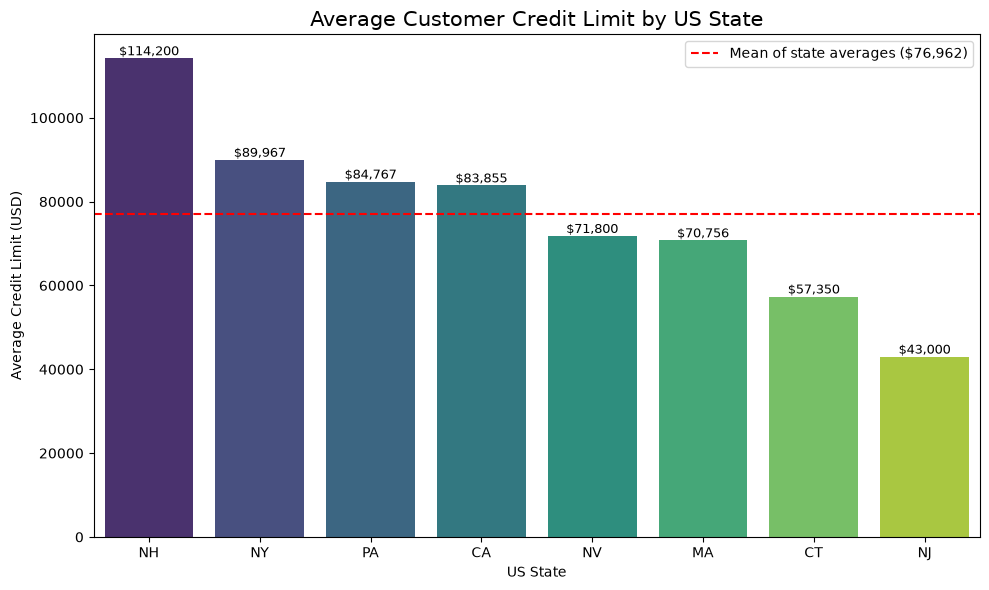

In [5]:
# Produce a visual to represent the average credit limit by state
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=avg_credit_by_state, x='state', y='avg_credit_limit',
            hue='state', palette='viridis', legend=False, ax=ax)
overall = avg_credit_by_state['avg_credit_limit'].mean()
ax.axhline(overall, color='red', linestyle='--', label=f'Mean of state averages (${overall:,.0f})')
for p in ax.patches:
    ax.annotate(f"${p.get_height():,.0f}", (p.get_x()+p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)
ax.set_title('Average Customer Credit Limit by US State', fontsize=15)
ax.set_xlabel('US State')
ax.set_ylabel('Average Credit Limit (USD)')
ax.legend()
plt.tight_layout()
plt.show()

### Step 4: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [6]:
# Top 10 customers by total payments
q5 = """
SELECT c.customerNumber, c.customerName,
       ROUND(SUM(CAST(p.amount AS REAL)), 2) AS total_payments
FROM customers c
JOIN payments p ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10;
"""
top_customers = pd.read_sql(q5, conn)
top_customers

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

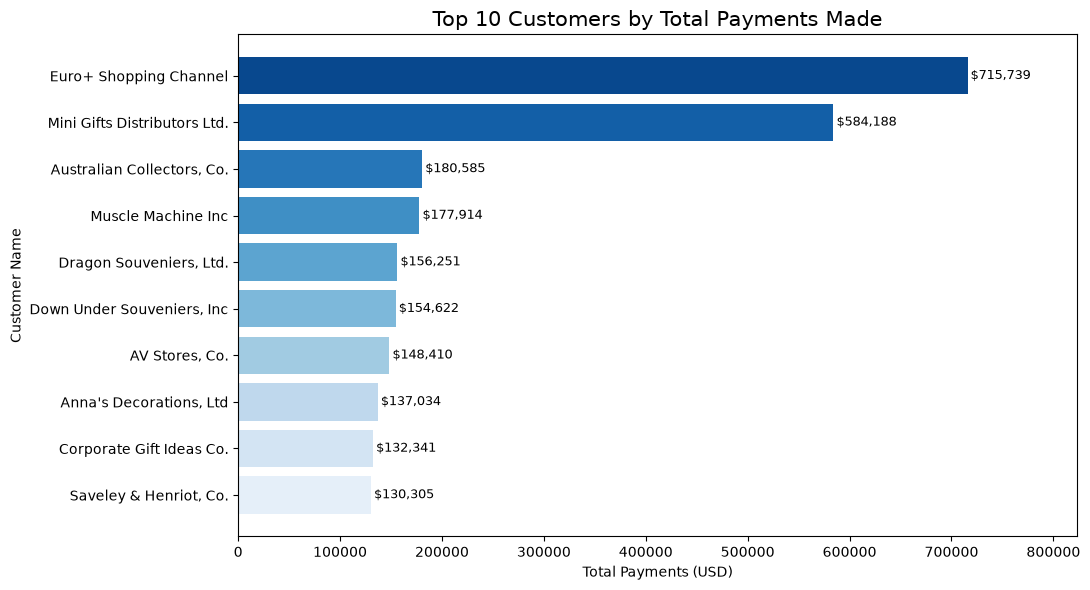

In [7]:
# Produce a visual to represent the top ten customers in terms of total payments
fig, ax = plt.subplots(figsize=(11, 6))
plot_df = top_customers.sort_values('total_payments')
bars = ax.barh(plot_df['customerName'], plot_df['total_payments'], color=sns.color_palette('Blues', 10))
for b in bars:
    ax.text(b.get_width()+3000, b.get_y()+b.get_height()/2, f"${b.get_width():,.0f}", va='center', fontsize=9)
ax.set_title('Top 10 Customers by Total Payments Made', fontsize=15)
ax.set_xlabel('Total Payments (USD)')
ax.set_ylabel('Customer Name')
ax.set_xlim(0, plot_df['total_payments'].max()*1.15)
plt.tight_layout()
plt.show()

### Step 5: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [8]:
# Products each customer purchased 10+ units of, sorted ascending by total quantity
q6 = """
SELECT c.customerNumber, c.customerName,
       p.productCode, p.productName,
       SUM(od.quantityOrdered) AS total_quantity
FROM customers c
JOIN orders o        ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber    = od.orderNumber
JOIN products p      ON od.productCode   = p.productCode
GROUP BY c.customerNumber, c.customerName, p.productCode, p.productName
HAVING SUM(od.quantityOrdered) >= 10
ORDER BY total_quantity ASC;
"""
customer_products = pd.read_sql(q6, conn)
customer_products

,customerNumber,customerName,productCode,productName,total_quantity
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 6: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [9]:
# Per product line: total quantity ordered and number of distinct products
# COUNT(DISTINCT ...) is needed because each product appears in many order lines,
# which would otherwise inflate the product count after the join.
q7 = """
SELECT pl.productLine,
       COUNT(DISTINCT p.productCode) AS num_products,
       SUM(od.quantityOrdered)       AS total_quantity_ordered
FROM productlines pl
JOIN products p       ON pl.productLine = p.productLine
JOIN orderdetails od  ON p.productCode  = od.productCode
GROUP BY pl.productLine
ORDER BY total_quantity_ordered DESC;
"""
product_line_df = pd.read_sql(q7, conn)
product_line_df

,productLine,num_products,total_quantity_ordered
0,Classic Cars,37,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

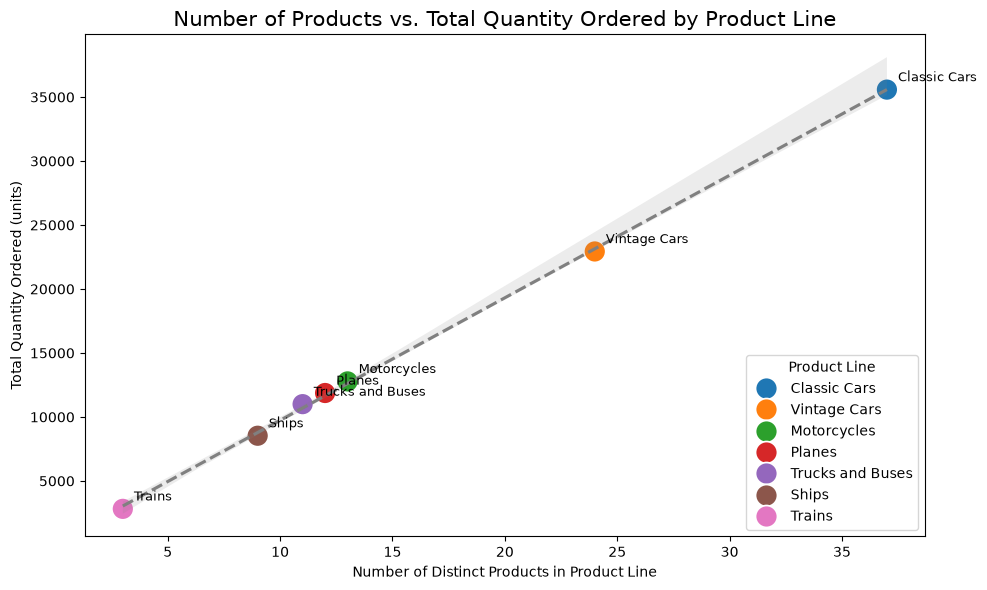

In [10]:
# Produce a visual to represent the relation between number of products and the total amount ordered
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=product_line_df, x='num_products', y='total_quantity_ordered',
                hue='productLine', s=250, palette='tab10', ax=ax)
for _, r in product_line_df.iterrows():
    ax.annotate(r['productLine'], (r['num_products'], r['total_quantity_ordered']),
                textcoords='offset points', xytext=(8, 6), fontsize=9)
sns.regplot(data=product_line_df, x='num_products', y='total_quantity_ordered',
            scatter=False, color='gray', line_kws={'linestyle': '--'}, ax=ax)
ax.set_title('Number of Products vs. Total Quantity Ordered by Product Line', fontsize=15)
ax.set_xlabel('Number of Distinct Products in Product Line')
ax.set_ylabel('Total Quantity Ordered (units)')
ax.legend(title='Product Line', loc='lower right')
plt.tight_layout()
plt.show()

**Reflection – chart choice (Step 6):**

I used a **scatter plot** because the question is about the *relationship between two numbers*: how many products a line offers (x) and how many units customers ordered from it (y). Each dot is one product line, so you can see at a glance whether lines with more products sit higher on the chart. I added a dashed trend line and labeled each dot. The picture shows a clear upward pattern: lines with bigger catalogs (Classic Cars, Vintage Cars) also sell the most units, while small lines (Trains, Ships) sell the fewest. So more products tends to go with more orders, but with only 7 product lines this is a preliminary signal, not proof. A bigger catalog may be *causing* more sales, or popular lines may simply have been expanded because they sell well.

### Step 7: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shutdown. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the revelant offices

Execute a SQl query that returns the information required to address this ask.

In [11]:
# Employees in offices with fewer than 5 employees, with job title, office, and supervisor
q8 = """
SELECT e.employeeNumber, e.firstName, e.lastName, e.jobTitle, e.email,
       e.officeCode, o.city AS office_city, o.country AS office_country,
       s.firstName || ' ' || s.lastName AS supervisor_name,
       s.jobTitle AS supervisor_title
FROM employees e
JOIN offices o ON e.officeCode = o.officeCode
LEFT JOIN employees s ON e.reportsTo = s.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(*) < 5
)
ORDER BY e.officeCode, e.lastName;
"""
remote_candidates = pd.read_sql(q8, conn)
remote_candidates

,employeeNumber,firstName,lastName,jobTitle,email,officeCode,office_city,office_country,supervisor_name,supervisor_title
0,1188,Julie,Firrelli,Sales Rep,jfirrelli@classicmodelcars.com,2,Boston,USA,Anthony Bow,Sales Manager (NA)
1,1216,Steve,Patterson,Sales Rep,spatterson@classicmodelcars.com,2,Boston,USA,Anthony Bow,Sales Manager (NA)
2,1286,Foon Yue,Tseng,Sales Rep,ftseng@classicmodelcars.com,3,NYC,USA,Anthony Bow,Sales Manager (NA)
3,1323,George,Vanauf,Sales Rep,gvanauf@classicmodelcars.com,3,NYC,USA,Anthony Bow,Sales Manager (NA)
4,1625,Yoshimi,Kato,Sales Rep,ykato@classicmodelcars.com,5,Tokyo,Japan,Mami Nishi,Sales Rep
5,1621,Mami,Nishi,Sales Rep,mnishi@classicmodelcars.com,5,Tokyo,Japan,Mary Patterson,VP Sales
6,1611,Andy,Fixter,Sales Rep,afixter@classicmodelcars.com,6,Sydney,Australia,William Patterson,Sales Manager (APAC)
7,1619,Tom,King,Sales Rep,tking@classicmodelcars.com,6,Sydney,Australia,William Patterson,Sales Manager (APAC)
8,1612,Peter,Marsh,Sales Rep,pmarsh@classicmodelcars.com,6,Sydney,Australia,William Patterson,Sales Manager (APAC)
9,1088,William,Patterson,Sales Manager (APAC),wpatterson@classicmodelcars.com,6,Sydney,Australia,Mary Patterson,VP Sales


**Reflection – subquery (Step 7):**

The requirement depends on the *size of each office*, which is not stored anywhere directly, so I had to compute it. The subquery groups `employees` by `officeCode` and uses `HAVING COUNT(*) < 5` to return only the office codes with fewer than 5 employees. The outer query then selects employees with `WHERE e.officeCode IN (subquery)`, so the list updates automatically if headcounts change, rather than hard-coding office codes. I also joined `offices` for the location and self-joined `employees` (as `s`) on `reportsTo = employeeNumber` to get each person's supervisor; a LEFT JOIN keeps anyone with no supervisor (e.g., the top executive) in the results.

### Step 8: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [12]:
# Close the connection
conn.close()

#### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertainent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overiew and instructions are also provided below.

In [13]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

1. A summary of your initial data exploration findings
    - Can be bulleted or paragraph form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

In [14]:
# Begin your code here
# 1) Scope of the data
pd.read_sql("""
SELECT COUNT(*) AS total_movies, MIN(start_year) AS min_year, MAX(start_year) AS max_year,
       SUM(runtime_minutes IS NULL) AS null_runtime, SUM(genres IS NULL) AS null_genres
FROM movie_basics
""", conn4)

,total_movies,min_year,max_year,null_runtime,null_genres
0,146144,2010,2115,31739,5408


In [15]:
# 2) Movies per year -- note the rows beyond 2019 that must be excluded
pd.read_sql("""
SELECT start_year, COUNT(*) AS num_movies
FROM movie_basics
GROUP BY start_year ORDER BY start_year
""", conn4)

,start_year,num_movies
0,2010,11849
1,2011,12900
2,2012,13787
3,2013,14709
4,2014,15589
5,2015,16243
6,2016,17272
7,2017,17504
8,2018,16849
9,2019,8379


In [16]:
# 3) Analysis set: 2010-2019, joined to ratings, with nulls excluded (not filled)
movies = pd.read_sql("""
SELECT b.movie_id, b.primary_title, b.start_year, b.runtime_minutes, b.genres,
       r.averagerating, r.numvotes
FROM movie_basics b
JOIN movie_ratings r ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND b.genres IS NOT NULL
  AND b.runtime_minutes IS NOT NULL
""", conn4)
print(len(movies), "rated movies after filtering")
movies.describe()

65720 rated movies after filtering


,start_year,runtime_minutes,averagerating,numvotes
count,65720.000000,65720.000000,65720.000000,6.572000e+04
mean,2014.258065,94.732273,6.320902,3.954674e+03
std,2.600143,209.377017,1.458878,3.208823e+04
min,2010.000000,3.000000,1.000000,5.000000e+00
25%,2012.000000,81.000000,5.500000,1.600000e+01
50%,2014.000000,91.000000,6.500000,6.200000e+01
75%,2016.000000,104.000000,7.300000,3.520000e+02
max,2019.000000,51420.000000,10.000000,1.841066e+06


In [17]:
# 4) Genres are comma-separated lists ("Action,Crime,Drama"), so split into one row per genre
genre_df = movies.assign(genre=movies['genres'].str.split(',')).explode('genre')
genre_stats = (genre_df.groupby('genre')
               .agg(num_movies=('movie_id', 'count'),
                    avg_rating=('averagerating', 'mean'),
                    median_votes=('numvotes', 'median'))
               .query('num_movies >= 500')          # drop tiny genres (e.g., Game-Show, Adult)
               .round(2).sort_values('avg_rating', ascending=False))
genre_stats

,num_movies,avg_rating,median_votes
genre,,,
Documentary,16423,7.32,21.0
News,575,7.28,19.0
Biography,3693,7.17,41.0
Music,1844,7.07,45.0
History,2704,7.05,40.0
Sport,1099,6.96,70.0
War,795,6.57,102.0
Musical,638,6.52,49.0
Family,3231,6.40,56.0


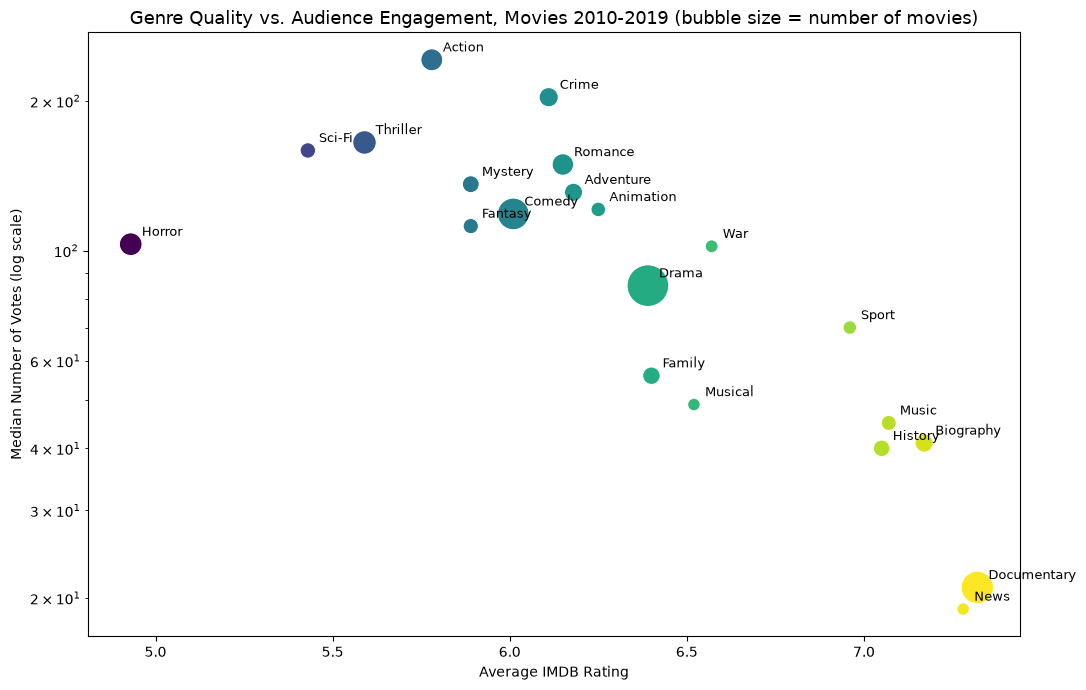

In [18]:
# 5) Visual: rating vs. audience engagement by genre
fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=genre_stats.reset_index(), x='avg_rating', y='median_votes',
                size='num_movies', sizes=(80, 900), hue='avg_rating', palette='viridis',
                legend=False, ax=ax)
for g, r in genre_stats.iterrows():
    ax.annotate(g, (r['avg_rating'], r['median_votes']), textcoords='offset points', xytext=(8, 6), fontsize=9)
ax.set_yscale('log')
ax.set_title('Genre Quality vs. Audience Engagement, Movies 2010-2019 (bubble size = number of movies)', fontsize=13)
ax.set_xlabel('Average IMDB Rating')
ax.set_ylabel('Median Number of Votes (log scale)')
plt.tight_layout()
plt.show()

In [19]:
# 6) Quick check: does runtime relate to rating? (also reveals runtime outliers)
print(movies[['runtime_minutes', 'averagerating']].corr().round(3))
print("Movies with runtime > 300 min:", (movies['runtime_minutes'] > 300).sum())
print("Rated movies with fewer than 20 votes:", (movies['numvotes'] < 20).sum())
# Duplicate titles within the same year (possible duplicate records)
pd.read_sql("""
SELECT COUNT(*) AS duplicate_title_year_groups FROM (
  SELECT primary_title, start_year FROM movie_basics GROUP BY 1, 2 HAVING COUNT(*) > 1)
""", conn4)

                 runtime_minutes  averagerating
runtime_minutes            1.000         -0.007
averagerating             -0.007          1.000
Movies with runtime > 300 min: 43
Rated movies with fewer than 20 votes: 19072


,duplicate_title_year_groups
0,1870


### Summary of Initial Exploration Findings
- `movie_basics` has ~146K titles, but only ~73.9K have ratings; ~31.7K lack runtime and ~5.4K lack genres. Nulls were excluded, not filled.
- Start years run from 2010 to as far as 2115; about 1,060 titles are after 2019 and were excluded.
- After filtering (2010-2019, rated, non-null runtime and genre) ~65.7K movies remain.
- **Drama** (~28K), **Documentary** (~16K) and **Comedy** (~15.5K) are the most common genres.
- **Ratings vs. reach split:** Documentary, News, Biography, History and Music rate highest (about 7.0-7.3) but get few votes (median about 20-45). Action, Thriller, Sci-Fi and Crime get the most votes (median 160-240) but rate lower (about 5.4-6.1). Horror is lowest rated (about 4.9).
- Runtime shows essentially no correlation with rating (about -0.01).

### Business Question
**Which genres should a studio or streaming platform invest in to get both high audience ratings and high audience engagement (votes) among 2010-2019 releases, and has that balance changed over the decade?**

### Potential Data Cleaning Tasks
1. Exclude movies with `start_year` after 2019 (values go up to 2115).
2. Handle nulls in `runtime_minutes` (~31.7K), `genres` (~5.4K) and elsewhere; exclude, do not impute.
3. Split the multi-valued `genres` column (comma-separated) into one row per genre; normalize into a bridge table.
4. Treat runtime outliers (min 1 minute, max 51,420 minutes) and decide on valid bounds.
5. Remove or flag low-vote ratings (e.g., < 20 votes), since averages are unreliable.
6. Check duplicate records (~1,870 title/year pairs appear more than once) and `primary_title` vs. `original_title` inconsistencies.
7. Standardize text fields such as `region`/`language` codes in `movie_akas`, and review the `XWW` and null regions.
8. Verify data types (e.g., IDs and numeric columns stored as TEXT/REAL) and standardize category labels in `principals`.